# Starter Code for Coursework on Tabular Data

**To mak this code run, it is at the moment written to work with a different data set, but you should be able to adapt it to your data set. Predicting humidity levels from city sensor readings:** 
This dataset contains **simulated readings** associated with fictional sampling visits to real city names. They are **not actual weather observations**. Predict `Humidity_Level` (`Low`, `Moderate`, `High`) from six sensor readings. The `City` column identifies the sampling group, and is not an input feature. How does this example relate to your tabular data set?

Upload `city_humidity_training_data.csv` to the same folder before running. 

In [12]:
# BEGINNER NEURAL NETWORK: CLASIFYING SOME TARGET CLASS IN THIS CASE  AN EXAMPLE WITH HUMIDITY LEVEL
# This is SIMULATED  data, not real city weather measurements.
# Keep city_humidity_training_data.csv in the same folder as this file.

# ================================================================
# CITY HUMIDITY CLASSIFICATION 
# ================================================================
#
# In Section 4, choose ONE of the two train/test splitting methods.
# Option A is active. Option B is commented out.
# ================================================================

# ---------------------------------------------------------------
# 1. IMPORT THE LIBRARIES
# ---------------------------------------------------------------
# A library contains ready-made Python tools.
# pandas reads tables, NumPy handles numbers and matplotlib makes plots.
# scikit-learn helps us prepare our data without writing the maths.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer



In [ ]:
# ---------------------------------------------------------------
# 2A. LOAD AND INSPECT THE DATA
# ---------------------------------------------------------------
# Each ROW is an observation from a simulated city sensor system.
# The sensor columns contain the measurements we will use as inputs.
# Humidity_Level is the category we want to predict.

df = pd.read_csv("simple_tabular_training_data.csv")
print("Dataset size:", df.shape)
print(df.head())

Dataset size: (1020, 8)
        City  sensor_01  sensor_02  sensor_03  sensor_04  sensor_05  \
0  Cambridge      75.76      67.33      18.76      84.26      46.86   
1  Edinburgh      61.95      53.81      48.45      59.42      36.41   
2  Liverpool      34.36      27.82      66.48      21.71      32.50   
3  Liverpool      82.45      69.96      12.80      95.82      40.27   
4     London      46.01      35.40      47.35      48.14      39.48   

   sensor_06 Humidity_Level  
0      42.83           High  
1      42.22       Moderate  
2      36.59            Low  
3      42.40           High  
4      20.13       Moderate  


In [ ]:
# ---------------------------------------------------------------
# 2B. SOME VISUALISATION ON CLASSES
# ---------------------------------------------------------------

#YOU CAN ADD HERE CODE FROM classImbalanceVisualisation.ipynb TO SEE THE SPREAD OF OBSERVATIONS PER CLASS IN GENERAL
#AS WELL AS THE SPREAD OF SAMPLES BY CLASS BY GROUP (E.G. MACHINE, TOOL, LOCATION, REFERNCE CITY..ETC)



In [ ]:
# ---------------------------------------------------------------
# 3. CHOOSE INPUT FEATURES (X) AND TARGET LABELS (y)
# ---------------------------------------------------------------
# X = the information we use to make a prediction (sensor readings).
# y = the correct answer we want the model to learn (humidity class).
# City identifies where the reading came from. It is NOT a sensor.
# We remove rows that have no answer (missing Humidity_Level).
# We exclude City and the answer itself from X to avoid leakage.

df = df.dropna(subset=["Humidity_Level"]).copy()
exclude = ["City", "Humidity_Level"]
X = df.drop(columns=exclude)
y = df["Humidity_Level"]
groups = df["City"]   # Only used in splitting Option B

print("\nInput columns:", X.columns.tolist())
print("\nMissing sensor values:\n", X.isna().sum())
print("\nHumidity categories:\n", y.value_counts())


# A computer works more easily with numbers than with text labels.
# LabelEncoder turns categories such as 'Low' into integer class IDs.
encoder = LabelEncoder()
y = encoder.fit_transform(y)
print("\nClass names:", encoder.classes_)


Input columns: ['sensor_01', 'sensor_02', 'sensor_03', 'sensor_04', 'sensor_05', 'sensor_06']

Missing sensor values:
 sensor_01    0
sensor_02    0
sensor_03    0
sensor_04    0
sensor_05    0
sensor_06    0
dtype: int64

Humidity categories:
 Humidity_Level
Moderate    388
Low         319
High        313
Name: count, dtype: int64

Class names: ['High' 'Low' 'Moderate']


In [ ]:
# ---------------------------------------------------------------
# 4. SPLIT INTO TRAINING, VALIDATION AND TEST SETS
# ---------------------------------------------------------------
# Training: the examples used for learning.
# Validation: examples used to compare model settings while developing.
# Test: examples held back for a final check on unseen observations.
#
# CHOOSE ONE OPTION BELOW. Do NOT run both.
# To switch methods, add # to every active line in Option A,
# then remove the # symbols from the code lines in Option B.
#
# OPTION A — RANDOM SPLIT (ACTIVE)
# Easier for beginners. Approximately 64% train, 16% validation,
# 20% test. stratify keeps class proportions approximately similar.
# Readings from the same city MAY appear in different sets.

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
)

# OPTION B — GROUPED BY CITY (COMMENTED OUT)
# A city cannot appear in more than one set. This asks a harder question:
# Can the model make predictions for cities it never saw in training?
# The class proportions are NOT guaranteed to match across sets.
#
#IF YOU WANT TO SPLIT BY CITY - SPLITTED IN A GROUPED WAY FROM WHERE MEASREMENTS COME FROM, LOOK AT SplittingDatabyGroup.ipynb


print("\nTraining rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))



Training rows: 652
Validation rows: 164
Test rows: 204


In [ ]:
# ---------------------------------------------------------------
# 5. FILL IN MISSING SENSOR READINGS
# ---------------------------------------------------------------
# A missing reading is shown as NaN. Machine learning algorithms
# generally need numerical values rather than gaps.
# We fill gaps with the MEDIAN value of that sensor column.
# IMPORTANT: calculate medians from TRAINING data only. Using the
# validation or test data to calculate them would cause data leakage.
# This example assumes no sensor column is entirely empty in training.

imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_val = imputer.transform(X_val)
X_test = imputer.transform(X_test)



In [ ]:
# ---------------------------------------------------------------
# 6. SCALE SENSOR READINGS
# ---------------------------------------------------------------
# Some sensors have much larger numbers than others. StandardScaler
# puts features on comparable scales, which helps a neural network
# learn and makes SMOTE's distance calculations more meaningful.
# Again, we learn the scaling from TRAINING data only.

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [ ]:
# ---------------------------------------------------------------
# 7. BUILD A SMALL NEURAL NETWORK
# ---------------------------------------------------------------
# A neural network learns patterns between sensor measurements and
# the humidity categories. This network has ONE hidden layer.
# Students: experiment with ONLY the three numbers below.
# NEURONS controls the hidden layer size.
# EPOCHS controls how many times the model studies the data.
# BATCH_SIZE controls how many examples it processes at once.

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)

NEURONS = 32       # Try 16, 32, or 64
EPOCHS = 50        # Try 20, 50, or 100
BATCH_SIZE = 32    # Try 16 or 32

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(NEURONS, activation="relu"),
    Dense(len(encoder.classes_), activation="softmax")
])

# The optimizer updates the model's weights as it learns.
# The loss tells it how far its predictions are from the labels.
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 323 (1.26 KB)

 Trainable params: 323 (1.26 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ---------------------------------------------------------------
# 8. TRAIN THE NETWORK
# ---------------------------------------------------------------
# The model learns ONLY from X_train and y_train.
# Validation data monitors how well it works on held-out examples.
# The test set is not used in this step.

history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val)
)


Epoch 1/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.5092 - loss: 0.9075 - val_accuracy: 0.6220 - val_loss: 0.7964
Epoch 2/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6518 - loss: 0.7342 - val_accuracy: 0.6341 - val_loss: 0.6713
Epoch 3/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6779 - loss: 0.6376 - val_accuracy: 0.6707 - val_loss: 0.6001
Epoch 4/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7255 - loss: 0.5753 - val_accuracy: 0.7256 - val_loss: 0.5493
Epoch 5/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7699 - loss: 0.5274 - val_accuracy: 0.7683 - val_loss: 0.5078
Epoch 6/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8144 - loss: 0.4872 - val_accuracy: 0.7988 - val_loss: 0.4714
Epoch 7/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8390 - loss: 0.4520 - val_accuracy: 0.8171 - val_loss: 0.4390
Epoch 8/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8558 - loss: 0.4204 - val_accuracy: 0.8659 - val_loss

In [ ]:
# ---------------------------------------------------------------
# 9. EVALUATE ON THE TEST SET
# ---------------------------------------------------------------
# Accuracy is the fraction of correct predictions.
# The classification report also shows performance for each class.
# Use validation results when choosing settings, and reserve test
# results for checking the final choice.

loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest accuracy: {accuracy * 100:.1f}%")

probabilities = model.predict(X_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))


Test accuracy: 91.2%

Classification report:
              precision    recall  f1-score   support

        High       0.95      0.95      0.95        62
         Low       0.88      0.94      0.91        64
    Moderate       0.91      0.86      0.88        78

    accuracy                           0.91       204
   macro avg       0.91      0.92      0.91       204
weighted avg       0.91      0.91      0.91       204



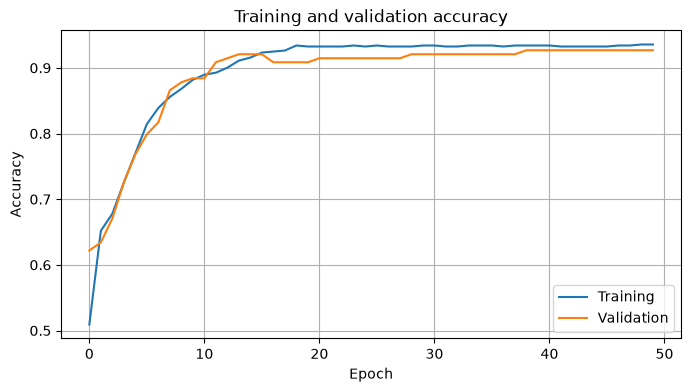

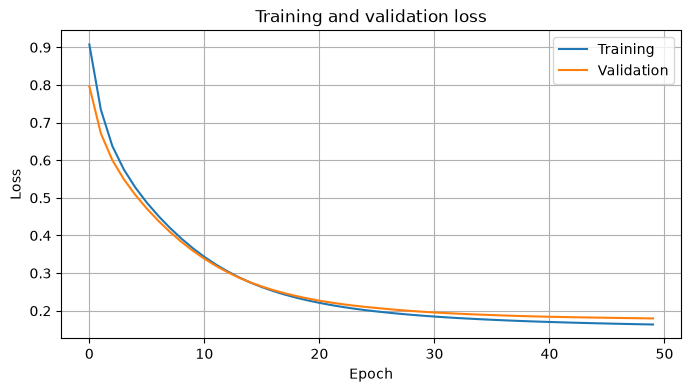

In [ ]:
# ---------------------------------------------------------------
# 10. PLOT HOW LEARNING CHANGED OVER TIME
# ---------------------------------------------------------------
# Accuracy should generally rise as the network learns.
# Loss should generally fall. If training improves while validation
# gets worse, the model may be overfitting.

plt.figure(figsize=(8, 4))
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and validation accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and validation loss")
plt.legend()
plt.grid(True)
plt.show()

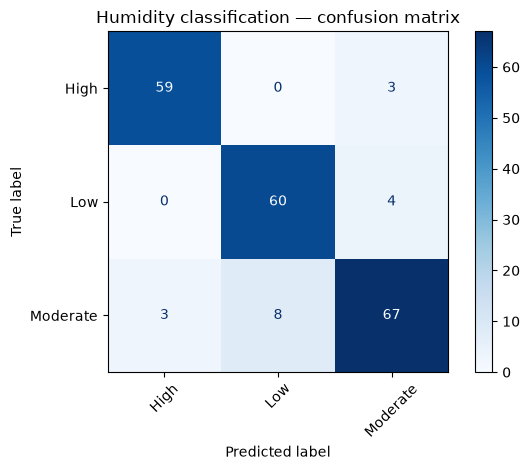


Ten example predictions:
  Actual humidity Predicted humidity
0            High               High
1             Low                Low
2        Moderate           Moderate
3             Low                Low
4             Low                Low
5            High               High
6        Moderate           Moderate
7            High               High
8            High               High
9            High               High


In [ ]:
# ---------------------------------------------------------------
# 11. EXAMINE THE MODEL'S MISTAKES
# ---------------------------------------------------------------
# A confusion matrix compares true classes with predicted classes.
# Values along the diagonal are correct predictions.
# The table underneath shows ten individual examples.

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=np.arange(len(encoder.classes_)),
    display_labels=encoder.classes_,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("Humidity classification — confusion matrix")
plt.tight_layout()
plt.show()

results = pd.DataFrame({
    "Actual humidity": encoder.inverse_transform(y_test),
    "Predicted humidity": encoder.inverse_transform(y_pred)
})
print("\nTen example predictions:")
print(results.head(10))

## Questions
1. Which columns are inputs and which column is the output?
2. What happens when you increase the number of neurons?
3. Do training and validation accuracy differ? Why?
4. Why do we keep each city in only one of training, validation or test? how does this relatees to the coursework tabular data sets?
